# NHL: анализ статистики команд

**Тестовое задание • 100 баллов**

Вы аналитик, которому передали готовую таблицу с исторической статистикой команд NHL.
Изучите данные, проверьте их, постройте графики и объясните свои наблюдения.
В работе оцениваются чтение данных, анализ, графики и обоснованность выводов.

Ориентир времени: 3-5 часов (знание хоккея не требуется).
Можно обращаться к документации и пользоваться вспомогательными инструментами.
Укажите, чем пользовались; отвечайте за правильность и понимание сданной работы.
Подтверждайте ответы результатами из своего ноутбука.

## Что сдавать

Выполненный IPynb с видимыми результатами и ответами разместите на платформе githib.com.
Укажите имя, дату и используемые инструменты укажите в README.
Файл `data/hockey_raw.csv` уже приложен к заданию. Исходный файл сохраняйте без изменений.
Для развёрнутого ответа обычно достаточно 3-6 содержательных предложений.
Каждый такой ответ должен ссылаться на ваши числа, строки или графики.

## Данные

Одна строка соответствует одной команде в одном сезоне. Значение `year` является
меткой сезона на сайте. Источник готовой таблицы:
[Scrape This Site - Hockey Teams](https://www.scrapethissite.com/pages/forms/).
Работайте с приложенным CSV; обращения к сайту для выполнения задания не нужны.

| Столбец | Значение |
|---|---|
| `team` | Название команды |
| `year` | Метка сезона |
| `wins` | Победы |
| `losses` | Поражения |
| `ot_losses` | Поражения в дополнительное время, если значение указано |
| `win_rate` | Доля побед, указанная в источнике |
| `goals_for` | Забитые шайбы |
| `goals_against` | Пропущенные шайбы |
| `goal_diff` | Разница забитых и пропущенных шайб |

Пустое значение в `ot_losses` рассматривайте как пропуск.
Для графиков указывайте заголовок и подписи осей с единицами измерения.
При объяснении причин отделяйте то, что видно в таблице, от предположений.

## Баллы

| Раздел | Баллы |
|---|---:|
| 1. Загрузка и проверка | 25 |
| 2. Таблицы и группировка | 25 |
| 3. Графики | 30 |
| 4. Интерпретация | 20 |
| **Всего** | **100** |

Выполняйте пункты по порядку. Каждый пункт оценивается отдельно.

**Автор:** Литвинов Михаил Сергеевич  
**Дата:** 13.10.2026  
**Использованные источники и инструменты:** документация seaborn, pandas; stackoverflow, чуууть чуть gemini

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

вы не выдали датасет, так что получаю его сам(

In [2]:
# url = "https://www.scrapethissite.com/pages/forms/?page_num={}&per_page=100"
# from io import StringIO
# import requests
# def get(p):
#     print(p)
#     return pd.read_html(StringIO(requests.get(url.format(p), headers={"User-Agent": "Mozilla/5.0"}).text))[0]

# df = pd.concat(get(p) for p in range(1, 7))
# df.columns = ["team", "year", "wins", "losses", "ot_losses", "win_rate", "goals_for", "goals_against", "goal_diff"]
# df.describe()
# df.to_csv("data/hockey_raw.csv")


## 1.1. Загрузите таблицу: 5 баллов

Прочитайте приложенный CSV в pandas. Покажите первые пять строк,
        число строк и столбцов. Какие наблюдения представляет одна строка?

In [3]:
df = pd.read_csv("data/hockey_raw.csv")

df.head(5)

,Unnamed: 0,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25


In [4]:
df.shape

(582, 10)

**Ответ 1.1:**

Одна строка представляет количество побед, поражений, поражений в овертайме, винрейт, количество забитых шайб, пропущенных шайб и разница забитых и пропущенных

## 1.2. Разберитесь со столбцами: 6 баллов

Выведите названия и типы столбцов. Посчитайте число разных команд и годов.
        Проверьте, повторяется ли пара `team` и `year`. Объясните результат проверки.

In [5]:
df.dtypes

Unnamed: 0         int64
team                 str
year               int64
wins               int64
losses             int64
ot_losses        float64
win_rate         float64
goals_for          int64
goals_against      int64
goal_diff          int64
dtype: object

In [6]:
df["team"].value_counts()

team
Boston Bruins              21
Buffalo Sabres             21
Calgary Flames             21
Chicago Blackhawks         21
Detroit Red Wings          21
Edmonton Oilers            21
Los Angeles Kings          21
Montreal Canadiens         21
New Jersey Devils          21
New York Islanders         21
New York Rangers           21
Philadelphia Flyers        21
Pittsburgh Penguins        21
St. Louis Blues            21
Toronto Maple Leafs        21
Vancouver Canucks          21
Washington Capitals        21
San Jose Sharks            20
Ottawa Senators            19
Tampa Bay Lightning        19
Dallas Stars               18
Florida Panthers           18
Colorado Avalanche         16
Phoenix Coyotes            15
Carolina Hurricanes        14
Nashville Predators        13
Mighty Ducks of Anaheim    12
Atlanta Thrashers          11
Columbus Blue Jackets      11
Minnesota Wild             11
Hartford Whalers            7
Winnipeg Jets               7
Anaheim Ducks               6
Quebe

In [7]:
df["year"].value_counts()

year
2000    30
2001    30
2002    30
2003    30
2005    30
2006    30
2007    30
2008    30
2009    30
2010    30
2011    30
1999    28
1998    27
1993    26
1994    26
1995    26
1996    26
1997    26
1992    24
1991    22
1990    21
Name: count, dtype: int64

In [8]:
df.duplicated(subset=["team", "year"]).sum()

np.int64(0)

**Ответ 1.2:**

Ответы на первые два вопроса представлены в ячейках выше, пара team и year не повторяется (последняя ячейка)

## 1.3. Найдите пропуски: 8 баллов

Посчитайте число и долю пропусков по столбцам. Для `ot_losses` покажите
        число пропусков по годам. Как будете обращаться с этим полем в дальнейшем анализе
        и почему?

In [9]:
df.isna().sum()

Unnamed: 0         0
team               0
year               0
wins               0
losses             0
ot_losses        224
win_rate           0
goals_for          0
goals_against      0
goal_diff          0
dtype: int64

In [10]:
df.isna().mean()

Unnamed: 0       0.00000
team             0.00000
year             0.00000
wins             0.00000
losses           0.00000
ot_losses        0.38488
win_rate         0.00000
goals_for        0.00000
goals_against    0.00000
goal_diff        0.00000
dtype: float64

In [11]:
df.groupby("year")["ot_losses"].apply(lambda x: x.isna().mean())

year
1990    1.0
1991    1.0
1992    1.0
1993    1.0
1994    1.0
1995    1.0
1996    1.0
1997    1.0
1998    1.0
1999    0.0
2000    0.0
2001    0.0
2002    0.0
2003    0.0
2005    0.0
2006    0.0
2007    0.0
2008    0.0
2009    0.0
2010    0.0
2011    0.0
Name: ot_losses, dtype: float64

**Ответ 1.3:**

Пропуски присутсвуют только по столбцу ot_losses, потеряно чуть больше трети данных. Но если смотреть на разбивку по годам то становится понятно что до 1999 года данных по этому столбцу просто нет - поэтому если выбирать данные после 1999 года на этот столбец можно спокойно ориентироваться

## 1.4. Проверьте согласованность: 6 баллов

Проверьте, что `win_rate` лежит между 0 и 1, счётчики побед и голов
        неотрицательны, а `goal_diff` равен `goals_for - goals_against`.
        Сообщите, сколько строк нарушает каждое условие. Как бы вы поступили,
        если бы обнаружили нарушение?

In [12]:
df[(df['win_rate'] < 0) | (df['win_rate'] > 1)].shape[0]

0

In [13]:
df[(df['goals_for'] < 0)].shape[0]

0

In [14]:
df[(df['goals_against'] < 0)].shape[0]

0

In [15]:
(df['goal_diff'] != df['goals_for'] - df['goals_against']).sum()

np.int64(0)

**Ответ 1.4:**

Ошибочных данных в датаесете нет (каждый блок показывает 0 строк), если бы я увидел что win_rate лежит вне 1 и 0 я бы заменил его на None и не учитывал в дальнейшем исследовании, с goals_for и against скорее всего поступил бы так же (еще и goal_diff прийдется занулить, можно конечно высчитывать счетчики голов из goal_diff, но это будет странно, так как опять же, мы не знаем харрактер ошибки), потому что харрактер ошибки нам неизвестен, и на эти данные опираться опасно. Если все остальные данные будут корректны, но разница goals_for и against не будет равна goal_diff, я заменю значение goal_diff на разницу количества забитых и прощенных шайб

## 2.1. Опишите долю побед: 6 баллов

Найдите минимум, медиану, среднее и максимум `win_rate` по всей таблице.
        Сравните медиану и среднее. Что эти числа сообщают о типичном командном сезоне,
        а чего по ним узнать нельзя?

In [16]:
df["win_rate"].min()

np.float64(0.119)

In [17]:
df["win_rate"].median()

np.float64(0.463)

In [18]:
df["win_rate"].mean()

np.float64(0.4585189003436426)

In [19]:
df["win_rate"].max()

np.float64(0.756)

**Ответ 2.1:**

Все запрашиваемые значения получены в ячейках выше снизу вверх по порядку. Медиана почти равняется среднему, это значит что данные распределены примерно симметрично. А нельзя узнать все остальное - форму, минимальное и макисмальное значения и тд.


## 2.2. Сравните сезоны: 8 баллов

Для каждого года посчитайте число команд, медиану `wins` и медиану `win_rate`.
        Выведите таблицу целиком и отдельно сравните 1993, 1994 и 1995 годы.
        Как отличается картина по числу побед и по доле побед?

In [20]:
df.groupby("year")["team"].count()

year
1990    21
1991    22
1992    24
1993    26
1994    26
1995    26
1996    26
1997    26
1998    27
1999    28
2000    30
2001    30
2002    30
2003    30
2005    30
2006    30
2007    30
2008    30
2009    30
2010    30
2011    30
Name: team, dtype: int64

In [21]:
df.groupby("year")["wins"].median()

year
1990    34.0
1991    35.5
1992    40.0
1993    39.0
1994    20.5
1995    35.5
1996    35.0
1997    35.0
1998    34.0
1999    36.0
2000    36.5
2001    37.0
2002    35.5
2003    38.0
2005    42.0
2006    42.5
2007    41.5
2008    41.0
2009    40.0
2010    43.0
2011    41.0
Name: wins, dtype: float64

In [22]:
df.groupby("year")["win_rate"].median()

year
1990    0.4250
1991    0.4440
1992    0.4760
1993    0.4640
1994    0.4275
1995    0.4330
1996    0.4270
1997    0.4270
1998    0.4150
1999    0.4390
2000    0.4450
2001    0.4510
2002    0.4330
2003    0.4630
2005    0.5120
2006    0.5180
2007    0.5060
2008    0.5000
2009    0.4880
2010    0.5240
2011    0.5000
Name: win_rate, dtype: float64

**Ответ 2.2:**

Если смотреть отдельно на 1993, 1994 и 1995 годы, можно заметить что в 1994 году сильно просела медана количества побед (с почти 40 до 20), при этом медиана винрейта просела не сильно (при этом все количество команд всего было 26). Скорее всего в 1994 году было проведено меньше игр, из-за чего упало абсолютное значение побед, а относительное значение винрейта осталось +- прежним.

## 2.3. Найдите крайние результаты: 5 баллов

Покажите три строки с самой высокой и три с самой низкой `win_rate`.
        Укажите команду, год и значение. Как вы убедились, что сравниваете именно долю,
        а не число побед?

In [23]:
df.sort_values(by="win_rate", ascending=False).head(3)

,Unnamed: 0,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
126,26,Detroit Red Wings,1995,62,13,NaN,0.756,325,181,144
382,82,Detroit Red Wings,2005,58,16,8.0,0.707,305,209,96
99,99,Detroit Red Wings,1994,33,11,NaN,0.688,180,117,63


In [24]:
df.sort_values(by="win_rate", ascending=True).head(3)

,Unnamed: 0,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
56,56,Ottawa Senators,1992,10,70,NaN,0.119,202,395,-193
60,60,San Jose Sharks,1992,11,71,NaN,0.131,218,414,-196
82,82,Ottawa Senators,1993,14,61,NaN,0.167,201,397,-196


**Ответ 2.3:**

Самый высокий win_rate равен 0.756 и был в 1995 году у команды Detroit Red Wings (и в целом эта команда входит в топ 3 по win_rate)  
Самый низкий win_rate равен 0.119 и был в 1992 году у команды Ottawa Senators
не совсем понимаю последний вопрос, win_rate сам по себе представляет собой долю побед в количестве матчей (???)

## 2.4. Выберите команду: 6 баллов

Выберите команду, представленную не менее чем в пяти сезонах.
        Покажите её строки по годам и найдите сезон с минимальной и максимальной
        долей побед. Почему сравнивать только название команды без года неудобно?

In [25]:
# так как у нас пара team-year не повторяется, можно точно сказать что одно появление команды = один сезон
df["team"].value_counts()

team
Boston Bruins              21
Buffalo Sabres             21
Calgary Flames             21
Chicago Blackhawks         21
Detroit Red Wings          21
Edmonton Oilers            21
Los Angeles Kings          21
Montreal Canadiens         21
New Jersey Devils          21
New York Islanders         21
New York Rangers           21
Philadelphia Flyers        21
Pittsburgh Penguins        21
St. Louis Blues            21
Toronto Maple Leafs        21
Vancouver Canucks          21
Washington Capitals        21
San Jose Sharks            20
Ottawa Senators            19
Tampa Bay Lightning        19
Dallas Stars               18
Florida Panthers           18
Colorado Avalanche         16
Phoenix Coyotes            15
Carolina Hurricanes        14
Nashville Predators        13
Mighty Ducks of Anaheim    12
Atlanta Thrashers          11
Columbus Blue Jackets      11
Minnesota Wild             11
Hartford Whalers            7
Winnipeg Jets               7
Anaheim Ducks               6
Quebe

In [26]:
# чтобы было интересно выберем например Dallas Stars
df[df["team"] == "Dallas Stars"].sort_values(by="win_rate")

,Unnamed: 0,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
125,25,Dallas Stars,1995,26,42,NaN,0.317,227,280,-53
98,98,Dallas Stars,1994,17,23,NaN,0.354,136,135,1
291,91,Dallas Stars,2001,36,28,5.0,0.439,215,213,2
471,71,Dallas Stars,2008,36,35,11.0,0.439,230,257,-27
501,1,Dallas Stars,2009,37,31,14.0,0.451,237,254,-17
351,51,Dallas Stars,2003,41,26,2.0,0.500,194,175,19
72,72,Dallas Stars,1993,42,29,NaN,0.500,286,265,21
531,31,Dallas Stars,2010,42,29,11.0,0.512,227,233,-6
560,60,Dallas Stars,2011,42,35,5.0,0.512,211,222,-11
232,32,Dallas Stars,1999,43,23,6.0,0.524,211,184,27


**Ответ 2.4:**

Выбрана команда Dallas Stars  
Сезон с минимальной продуктивностью - 1995  
Сезон с максимальной продуктивностью - 2005  
Сранивать название команды без года неудобно потому что команда и сама лига в разные годы могла очень сильно меняться. Например та же Dallas Stars в 2005 году была одной из лучших, а вот в 1995 одной из худших, и без указания года почти невомзожно определить причину

## 3.1. Покажите распределение: 7 баллов

Постройте гистограмму `win_rate` для всех строк.
        Подпишите оси и объясните, в какой части шкалы расположено большинство наблюдений.
        Приведите числовое подтверждение из пункта 2.1.

<Axes: xlabel='win_rate', ylabel='Count'>

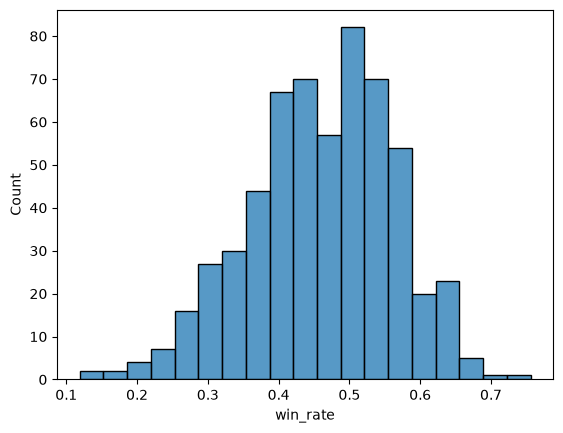

In [27]:
sns.histplot(df["win_rate"])

**Ответ 3.1:**

Большая часть наблюдений сосредоточена в окрестности 0.45-0.46, что и подтверждает совпадение среднего и медианного значения примерно в этих числах

## 3.2. Покажите изменение по годам: 8 баллов

Постройте линейный график медианы `win_rate` по годам из пункта 2.2.
        Подпишите оси. Найдите один год с заметно большей или меньшей медианой,
        чем у соседних доступных лет, и приведите числа. Отметьте в объяснении
        годы без данных.

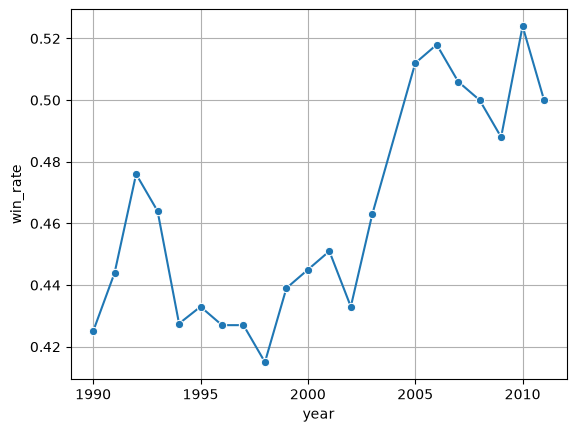

In [28]:
sns.lineplot(data=df, x="year", y="win_rate", estimator='median', errorbar=None, marker='o')
plt.grid(True)

**Ответ 3.2:**

У 2005 и последующих годов медиана заметно выше чем у прошлых 14 лет наблюдений - раньше она колебалась в пределах 0.42-0.48, а после этого поднялась до 0.48-0.52. При этом данных по 2004 году в датасете нет

## 3.3. Сравните голы и долю побед: 8 баллов

Постройте диаграмму рассеяния: `goal_diff` по горизонтали,
        `win_rate` по вертикали. Опишите общую связь и приведите две конкретные
        строки для иллюстрации. Можно ли по этому графику заключить, что знак
        `goal_diff` безошибочно определяет высокую долю побед?

<Axes: xlabel='goal_diff', ylabel='win_rate'>

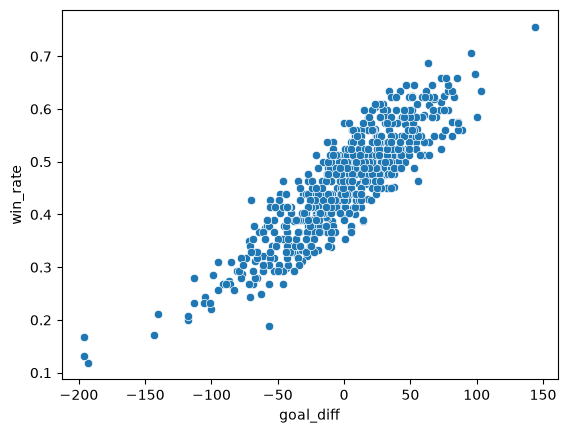

In [29]:
sns.scatterplot(data=df, x="goal_diff", y="win_rate")

In [30]:
# приведем пример почему именно ЗНАК может не влиять на "высокую долю побед"
df[(df["goal_diff"] < 0) & (df["win_rate"] > 0.53)].iloc[0]
# отрицательный goal_diff, но больший винрейт (>50% даже)

Unnamed: 0                        28
team             Tampa Bay Lightning
year                            2006
wins                              44
losses                            33
ot_losses                        5.0
win_rate                       0.537
goals_for                        253
goals_against                    261
goal_diff                         -8
Name: 428, dtype: object

In [31]:
df[(df["goal_diff"] > 0) & (df["win_rate"] < 0.4)].iloc[0]
# положительный goal diff, но меньший винрейт

Unnamed: 0                    1
team             Buffalo Sabres
year                       1990
wins                         31
losses                       30
ot_losses                   NaN
win_rate                  0.388
goals_for                   292
goals_against               278
goal_diff                    14
Name: 1, dtype: object

**Ответ 3.3:**

Корреляция этих двух переменных видна очень четко - чем выше goal_diff, тем выше win_rate. На этой диаграмме даже нету критичных выбросов, поэтому я бы сказал что можно с довольно большой уверенностью заявить что goal_diff безошибочно определяет долю побед (но не знак, но если сранивать допустим все что ниже -50 и все что выше +50 то можно именно точно заявлять)

## 3.4. Покажите историю выбранной команды: 7 баллов

Для команды из пункта 2.4 постройте график `win_rate` по годам.
        Укажите в ответе, есть ли годы без данных, и как вы показали их на графике.
        Найдите два соседних доступных сезона с заметным изменением
        и укажите значения в ответе.

<Axes: xlabel='year', ylabel='win_rate'>

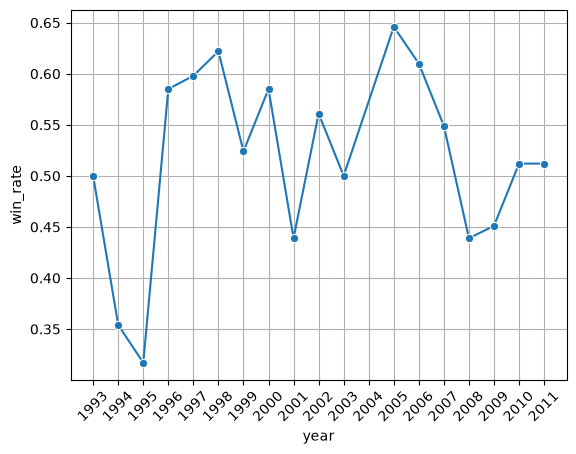

In [32]:
plt.xticks(range(1993, 2011 + 1, 1), rotation=45)
plt.grid(True)
sns.lineplot(data=df[df['team'] == "Dallas Stars"], x="year", y="win_rate", marker='o', )

**Ответ 3.4:**

Годы без данных есть - с 1990 года по 1992, и как и во всем датасете в 2004 году (на графике они показаны отсуствием маркеров)  
Огромное изменение произошло между 1995 и 1996 годами - винрейт с ниже 0.35 поднялся почи до 0.6

## 4.1. Проверьте последовательность лет: 5 баллов

Найдите все годы между минимальным и максимальным `year`,
        которых нет в таблице. Как отсутствие года может повлиять на линейный график?
        Сошлитесь на свой график из пункта 3.2.

In [33]:
set(range(df['year'].min(), df['year'].max()+1)) - set(df['year'])

{2004}

**Ответ 4.1:**

В датасете отсуствует только один год - 2004 (как и было замечено на графиках ранее). В моем случае на графике это отразилось интерполяцией - seaborn дорисовал недостающие данные. Лучше отражал бы отсутствие данных разрыв на графике, но мне лень его делать

## 4.2. Сравните число побед и долю: 6 баллов

Возьмите одну команду, которая есть в 1993, 1994 и 1995 годах.
        Выведите для неё `wins` и `win_rate` за эти годы.
        Какой вывод изменится, если смотреть только на число побед?
        Свяжите ответ с группировкой из пункта 2.2.

In [34]:
tby = df.groupby('year')['team'].apply(set)
tby[1993] & tby[1994] & tby[1995]

{'Boston Bruins',
 'Buffalo Sabres',
 'Calgary Flames',
 'Chicago Blackhawks',
 'Dallas Stars',
 'Detroit Red Wings',
 'Edmonton Oilers',
 'Florida Panthers',
 'Hartford Whalers',
 'Los Angeles Kings',
 'Mighty Ducks of Anaheim',
 'Montreal Canadiens',
 'New Jersey Devils',
 'New York Islanders',
 'New York Rangers',
 'Ottawa Senators',
 'Philadelphia Flyers',
 'Pittsburgh Penguins',
 'San Jose Sharks',
 'St. Louis Blues',
 'Tampa Bay Lightning',
 'Toronto Maple Leafs',
 'Vancouver Canucks',
 'Washington Capitals',
 'Winnipeg Jets'}

In [35]:
# возьмем допустиииим New Jersey Devils
df[(df["team"] == "New Jersey Devils") & (df["year"].isin([1993,1994,1995]))][["year", "wins", "win_rate"]]

,year,wins,win_rate
79,1993,47,0.560
105,1994,22,0.458
132,1995,37,0.451


**Ответ 4.2:**

Если смотреть только на число побед, можно подумать что команда сильно продула в 1994 году - но это из-за абсолютных значений, на самом деле относительная продуктивность команды упала меньше чем на 10%. С пунктом 2.2 это связано напрямую - количество побед просело очень сильно, а вот win_rate почти не изменился. Опять же можно сделать вывод что было просто сыграно меньше игр в целом

## 4.3. Найдите собственное наблюдение: 5 баллов

Найдите ещё один интересный вам пример в таблице или на графике.
        Укажите команду, год, два значения и пункт, результат которого
        помог вам заметить пример. Как он уточняет ваш общий вывод?

In [36]:
# посмотрим допустим Dallas Stars в 1995 и 2005 годах
df[(df['team'] == 'Dallas Stars') & (df['year'].isin([1995, 2005]))][['year', 'wins', 'win_rate', 'goal_diff']]

,year,wins,win_rate,goal_diff
125,1995,26,0.317,-53
381,2005,53,0.646,47


**Ответ 4.3:**

Еще подобное являение видно на примере команды Dallas Stars - в 1995 году она была среди худших с винрейтом 0.317 и goal_diff -53, а в 2005 стала достаточно продуктивной командой с винрейтом 0.646. Это еще лучше показывает что смотреть на статистику команд не учитывая год абсолютно нерепрезентативно. Помогли заметить это мне пункты 2.4 и 3.4.

## 4.4. Сформулируйте выводы: 4 баллов

Сформулируйте два вывода из своей работы. Для каждого приведите
        номер таблицы или графика и одно число. Назовите одно ограничение данных,
        которое важно помнить при чтении результатов.

**Ответ 4.4:**

Первый вывод: при оценке результативности команды важно смотреть не на абсолютное значение побед или поражений, а на показатель win_rate, так как он не зависит от количества сыгранных матчей в целом. Показано это в пункте 2.2, когда в 1994 году медианное количество побед у команд упало почти вдвое, медианный win_rate изменился не сильно.

Второй вывод: нельзя смотреть на результаты команд не учитывая год, так как в разные года у команд может быть разный состав, разные тактики и тд, наглядно видно это в пункте 3.4, win_rate изменяется от <0.35 до >0.6, в зависимости от года

При чтении результатов важно помнить про отсустствие подробной информации по команде (изменение состава команды или тренера например), изменений в правилах НХЛ, что может дополнительно влиять на результативность команд